In [6]:
import networkx # граф

from tqdm import tqdm #отслеживание прогресса выполнения 

import random 
from random import randint

from gensim.models import Word2Vec #word2vec
import warnings

#снижение размерности для визуализации
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
%matplotlib inline

from tqdm import tqdm 
import random 

from sklearn.cluster import MiniBatchKMeans
from sklearn.cluster import KMeans

!pip install scikit-learn-extra


from sklearn_extra.cluster import KMedoids
from sklearn import metrics
from sklearn.cluster import AffinityPropagation


Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 1.7 MB 4.9 MB/s 


1.Визуализация в cytoscape


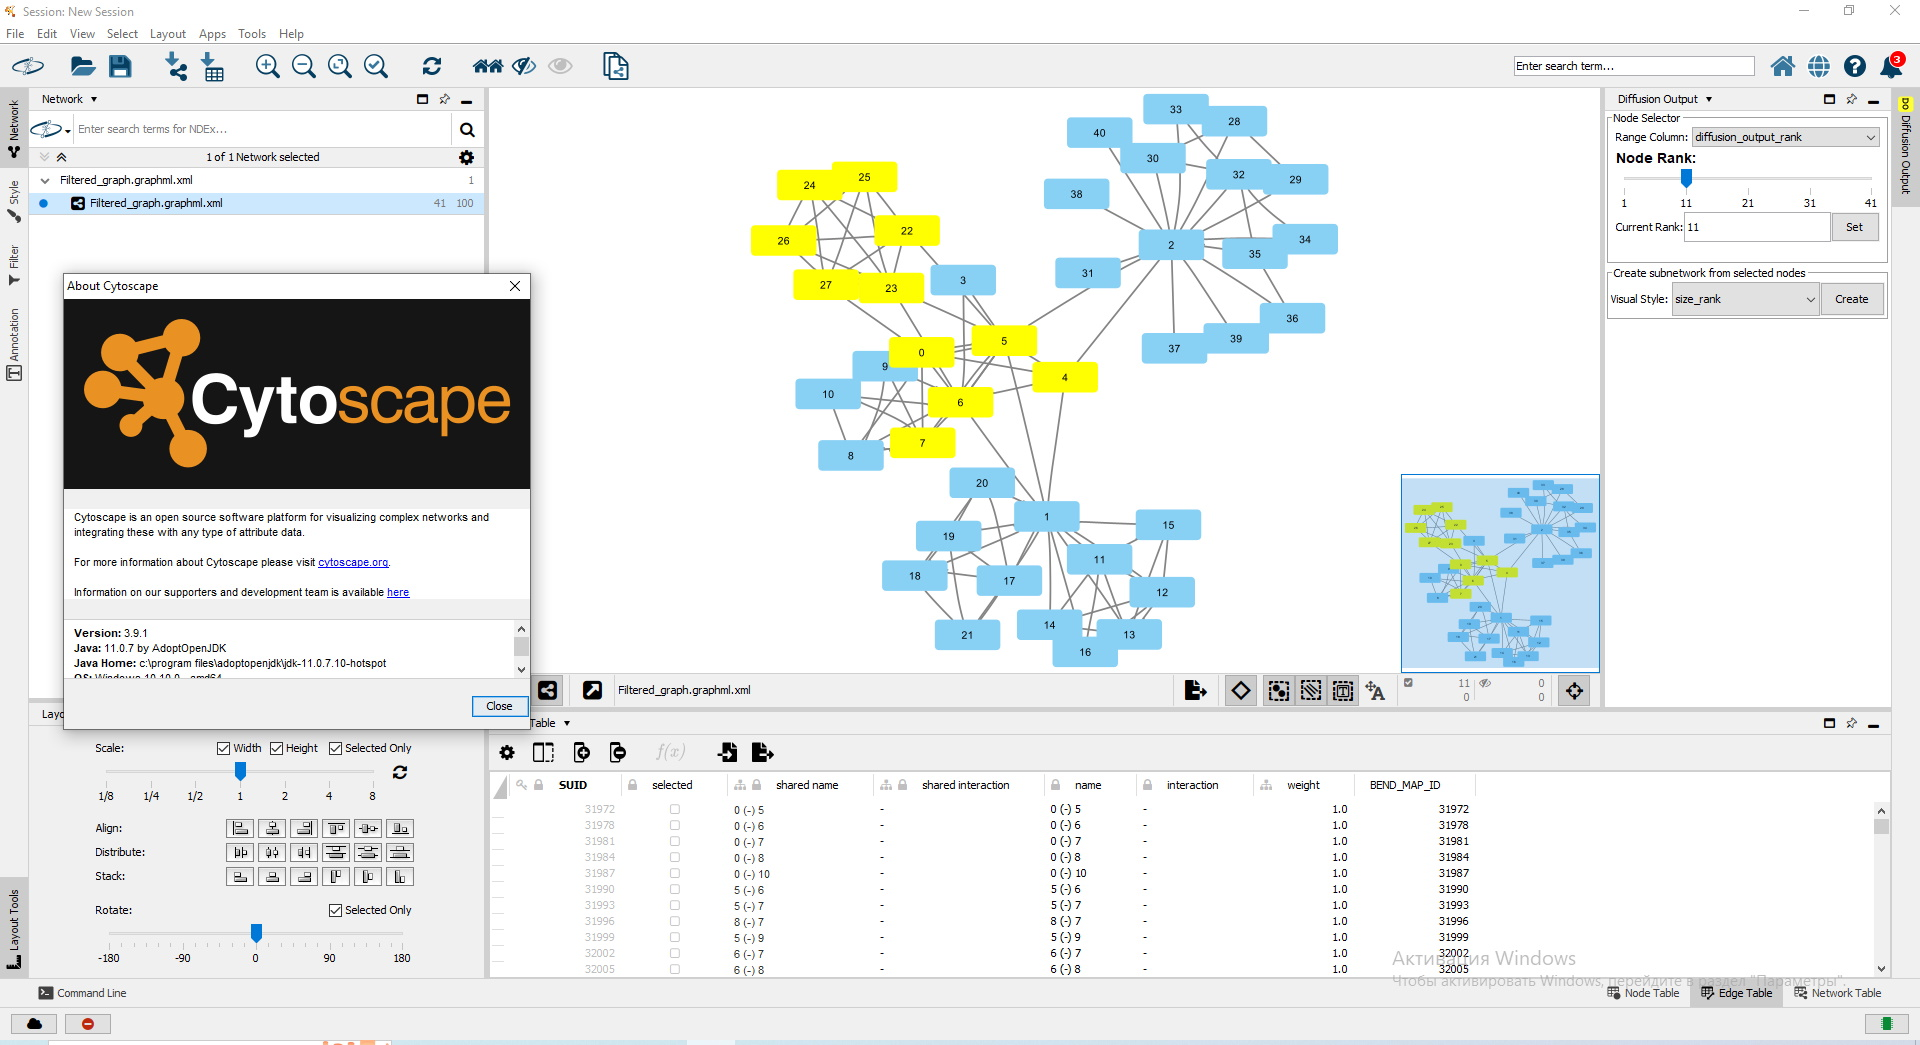

---



2. Число кластеров 4. Просто 3 ярко выраженных, 4 под вопросом и сильно зависит от заданного порога различий

In [4]:
from google.colab import files
#загрузка файла
#uploaded = files.upload()
# данные из файла преобразуются в граф
#!ls
G = networkx.readwrite.graphml.read_graphml('Filtered_graph.graphml.xml')

Необходимые фукнции


In [9]:
# path_lengh - соответствует параметру t (см. презентацию)
def get_randomwalk(G, node, path_length):
    
    random_walk = [node]
    #print ('начинаем с узла', random_walk)
    for i in range(path_length-1):
        temp = list(G.neighbors(node))
        # print('соседи', temp)
        temp = list(set(temp) - set(random_walk))    
        if len(temp) == 0:
            break

        random_node = random.choice(temp)
        random_walk.append(random_node)
        node = random_node
        
    return random_walk

def plot_nodes(node_list, X_embedding, labels = [], annotate = False, annotate_labes = {} ):
    X = X_embedding

    #цвет, при отсутствии меток кластера
    colors = ['#6495ED' for i in node_list]
    map={}
    #если метки кластера в наличии, то случайно выбираем цвета
    if len(labels) != 0:
       for i in set(labels):
         map[i]='#%06X' % randint(0, 0xFFFFFF)
       colors = [map[i] for i in labels]
    
    # уменьшаем размерность до 2х
    pca = PCA(n_components=2)
    result = pca.fit_transform(X)
    

    
    plt.figure(figsize=(6,3))
    # create a scatter plot of the projection

    plt.scatter(result[:, 0], result[:, 1],  c=colors)
    for i, node in enumerate(node_list):
         if (annotate_labes[node] !='-' and annotate ==True):
          plt.annotate(annotate_labes[node], xy=(result[i, 0], result[i, 1]))
    
    plt.show()



###------------------------
def plot_TSNE_nodes(node_list, X_embedding, labels = [], annotate = False, annotate_labes = {}):

    colors = ['#6495ED' for i in node_list]
    map={}
    if len(labels) != 0:
      for i in set(labels):
         map[i]='#%06X' % randint(0, 0xFFFFFF)
      colors = [map[i] for i in labels]
    X = X_embedding

    tsne = TSNE(n_components=2, verbose=0, perplexity=7)
    tsne_results = tsne.fit_transform(X)

    plt.figure(figsize=(9,6))
    # create a scatter plot of the projection
    plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c = colors)
    for i, node in enumerate(node_list):
        if (annotate_labes[node] !='-' and annotate ==True):
          plt.annotate(annotate_labes[node], xy=(tsne_results[i, 0], tsne_results[i, 1]))
    plt.show()

#### ОБА ГРАФИКА ДЛЯ СРАВНЕНИЯ ---------------------------
def plot_TSNE_PCA_nodes(node_list, X_embedding, labels = [], annotate = False, annotate_labes = {}):

    colors = ['#6495ED' for i in node_list]
    map={}
    if len(labels) != 0:
      for i in set(labels):
         map[i]='#%06X' % randint(0, 0xFFFFFF)
      colors = [map[i] for i in labels]
    X = X_embedding
    tsne = TSNE(n_components=2, verbose=0, perplexity=7)
    #perpexity	Степень хаоса, которая указывает, сколько соседних точек учитывается при оптимизации t-SNE,
    # по умолчанию 30, а рекомендуемое значение от 5 до 50
    tsne_results = tsne.fit_transform(X)

    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(X)
    
    f, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].scatter(pca_result[:, 0], pca_result[:, 1],  c=colors)
    ax[0].set_title('PCA Cluster Plot')

    ax[1].scatter(tsne_results[:, 0], tsne_results[:, 1], c = colors)
    ax[1].set_title('TSNE Cluster Plot') 
    plt.show()

   #функция выводит состав кластеров
#lab = метки кластеров
#G - граф
def print_clusters(lab, G, list_nodes):

  for k in list(set(lab)):
    print ("CLUSTER  ", k,"-----------------------------------------------------")
    j=0
    t=0
    for i in range(0, len(lab)):
      if lab[i]==k:
        t = t + 1
        itm =list_nodes[i]
        if G.nodes[itm]['label'] != "-":
          print (G.nodes[itm]['label'], ", id-", itm)
        else:
          j = j+1

    print ("Неразмеченных -", j)  
    print ("ВСЕГО в кластере  -", t)  

  
#оптимальное число кластеров 
def find_optimal_clusters(data, max_k):
    iters = range(2, max_k+1, 1)
    
    sse = []
    for k in iters:
        sse.append(MiniBatchKMeans(n_clusters=k, init_size=1024, batch_size=2048, random_state=20).fit(data).inertia_)
        print('Fit {} clusters'.format(k))
        
    f, ax = plt.subplots(1, 1)
    ax.plot(iters, sse, marker='o')
    ax.set_xlabel('Центры кластеров')
    ax.set_xticks(iters)
    ax.set_xticklabels(iters)
    ax.set_ylabel('SSE')
    ax.set_title('SSE by Cluster Center Plot') 

In [15]:
warnings.filterwarnings('ignore')

3. Эмбеддинг

In [43]:
all_nodes = list(G.nodes())
gamma = 80
t = 80
random_walks = []
for n in tqdm(all_nodes):
    for i in range(gamma):
        random_walks.append(get_randomwalk(G, n, t))
        
# полученное число случайных блужданий
#len(random_walks)

model = Word2Vec(window = 10, sg = 1, hs = 0, batch_words=3000,
                 negative = 10, # for negative sampling
                 alpha=0.03, min_alpha=0.005,
                 seed = 14)

model.build_vocab(random_walks, progress_per=2)

model.train(random_walks, total_examples = model.corpus_count, epochs=3, report_delay=1)
model[model.wv.vocab] # эмбеддинги
print(len(model[model.wv.vocab]))

100%|██████████| 41/41 [00:00<00:00, 454.65it/s]


41

In [19]:
X = model[model.wv.vocab] #эмбединги

model.wv.vocab # сами ключи - номера узлов

list_labels ={}
for node in G.nodes:
  list_labels[node]=G.nodes[node]['label']

list_labels 

{'0': 'Главный тренер-группа pro',
 '1': 'Тренер - группа любители, организатор 1',
 '2': 'Организатор 2',
 '3': 'Организатор 3(Дох)',
 '4': 'Спортивный врач-физиотерапевт',
 '5': 'Спортсмен-pro-1',
 '6': 'Спортсмен-pro-2',
 '7': 'Спортсмен-pro-3',
 '8': 'Спортсмен-pro-4',
 '9': 'Спортсмен-pro-5',
 '10': 'Спортсмен-pro-6',
 '11': 'Спортсмен-любитель 1',
 '12': 'Спортсмен-любитель 2',
 '13': 'Спортсмен-любитель 3',
 '14': 'Спортсмен-любитель 4',
 '15': 'Спортсмен-любитель 5',
 '16': 'Спортсмен-любитель 6',
 '17': 'Спортсмен-любитель 7',
 '18': 'Спортсмен-любитель 8',
 '19': 'Спортсмен-любитель 9',
 '20': 'Спортсмен-любитель 10',
 '21': 'Спортсмен-любитель 11',
 '22': 'Спортсмен-другой регион 1',
 '23': 'Спортсмен-другой регион 2',
 '24': 'Спортсмен-другой регион 3',
 '25': 'Спортсмен-другой регион 4',
 '26': 'Спортсмен-другой регион 5',
 '27': 'Тренер спортсменов др. регион',
 '28': 'Активный-участник 1',
 '29': 'Активный-участник 2',
 '30': 'Активный-участник 3',
 '31': 'Активный-участ

4.Визуализация

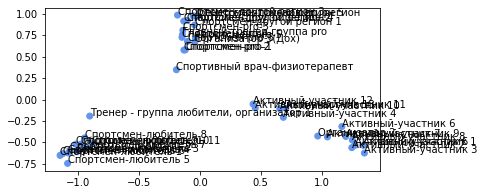

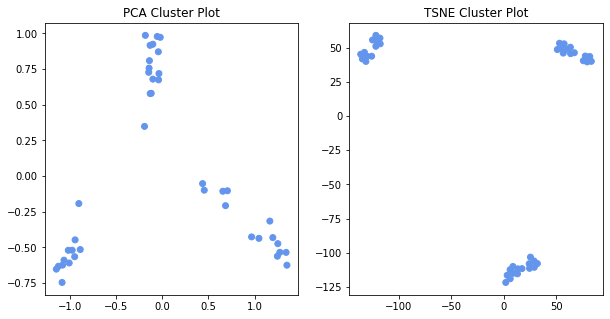

In [20]:
plot_nodes(node_list = list(model.wv.vocab), X_embedding=X, annotate=True, annotate_labes=list_labels)
plot_TSNE_PCA_nodes(node_list = list(model.wv.vocab), X_embedding=X, annotate=True, annotate_labes=list_labels)

5. Найти 3 узла, наиболее схожие с организатором

In [27]:
from six import viewitems
similar = model.wv.similar_by_word('1')
print("Узлы, схожие с 1  ", similar)
#Покажем в метки узлов и представим результат в более наглядном виде
for i in range(len(similar)):
  print (G.nodes[similar[i][0]]['label'] )
print(len(similar))

Узлы, схожие с 1   [('12', 0.9687588810920715), ('18', 0.967511773109436), ('16', 0.967103123664856), ('14', 0.9670184850692749), ('11', 0.9667457938194275), ('20', 0.9656776785850525), ('19', 0.9638937711715698), ('13', 0.9628950953483582), ('17', 0.9620521068572998), ('21', 0.9616700410842896)]
Спортсмен-любитель 2
Спортсмен-любитель 8
Спортсмен-любитель 6
Спортсмен-любитель 4
Спортсмен-любитель 1
Спортсмен-любитель 10
Спортсмен-любитель 9
Спортсмен-любитель 3
Спортсмен-любитель 7
Спортсмен-любитель 11
10


Результат 12,18,16

6. Узлы, схожие с главным тренером

In [28]:
#'0': 'Главный тренер-группа pro'
similar = model.wv.similar_by_word('0')
print("Узлы, схожие с главным тренером  ", similar)
for i in range(len(similar)):
  print (G.nodes[similar[i][0]]['label'] )
print(len(similar))

Узлы, схожие с главным тренером   [('8', 0.9982271790504456), ('7', 0.9975310564041138), ('10', 0.9968055486679077), ('3', 0.9964213371276855), ('9', 0.9955093860626221), ('23', 0.9950799345970154), ('5', 0.9946945309638977), ('22', 0.9934438467025757), ('6', 0.9926453232765198), ('25', 0.992357611656189)]
Спортсмен-pro-4
Спортсмен-pro-3
Спортсмен-pro-6
Организатор 3(Дох)
Спортсмен-pro-5
Спортсмен-другой регион 2
Спортсмен-pro-1
Спортсмен-другой регион 1
Спортсмен-pro-2
Спортсмен-другой регион 4
10


Ответ 8,7,10

7. Кластерный анализ

In [30]:
#DBScan
from sklearn.cluster import DBSCAN
import numpy as np
import sklearn

#X = model[model.wv.vocab]
#Она и так по умолчанию
CosDist = sklearn.metrics.pairwise.cosine_distances(X,X)

#можно двумя способами сделать
#db = DBSCAN(metric="precomputed", eps=0.5, min_samples=2).fit(CosDist) #Нет нужды, так как косинусная метрика и так используется по умолчанию
db = DBSCAN( metric='cosine', eps=0.05, min_samples=2).fit(X)
db.labels_

#оценка сколько получилось кластеров и сколько объектов отмечено как шумовых
n_clusters_ = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise_ = list(db.labels_).count(-1)
print("кластеров - ", n_clusters_, ", шум ", n_noise_, ", всего ", len(db.labels_) , ", метки кластеров", set(db.labels_))

print_clusters(db.labels_, G, list(model.wv.vocab))  
#Силуэт
print ("DBScan силуэт", metrics.silhouette_score( metric="precomputed", X=CosDist,   labels= db.labels_ ))


кластеров -  3 , шум  0 , всего  41 , метки кластеров {0, 1, 2}
CLUSTER   0 -----------------------------------------------------
Главный тренер-группа pro , id- 0
Спортсмен-pro-2 , id- 6
Спортсмен-pro-4 , id- 8
Спортсмен-pro-6 , id- 10
Спортсмен-pro-3 , id- 7
Спортсмен-pro-5 , id- 9
Спортсмен-pro-1 , id- 5
Организатор 3(Дох) , id- 3
Спортивный врач-физиотерапевт , id- 4
Спортсмен-другой регион 1 , id- 22
Спортсмен-другой регион 4 , id- 25
Спортсмен-другой регион 3 , id- 24
Спортсмен-другой регион 5 , id- 26
Спортсмен-другой регион 2 , id- 23
Тренер спортсменов др. регион , id- 27
Неразмеченных - 0
ВСЕГО в кластере  - 15
CLUSTER   1 -----------------------------------------------------
Тренер - группа любители, организатор 1 , id- 1
Спортсмен-любитель 11 , id- 21
Спортсмен-любитель 9 , id- 19
Спортсмен-любитель 10 , id- 20
Спортсмен-любитель 8 , id- 18
Спортсмен-любитель 7 , id- 17
Спортсмен-любитель 1 , id- 11
Спортсмен-любитель 3 , id- 13
Спортсмен-любитель 5 , id- 15
Спортсмен-любит

In [31]:
#Affiniti Propagation
from sklearn.cluster import AffinityPropagation

ap_cluster = AffinityPropagation( damping=0.9, max_iter=100, affinity='precomputed').fit(CosDist)
#оценка сколько получилось кластеров и сколько объектов отмечено как шумовых
n_clusters_ = len(set(ap_cluster.labels_)) - (1 if -1 in ap_cluster.labels_ else 0)
n_noise_ = list(db.labels_).count(-1)
print("кластеров - ", n_clusters_, ", шум ", n_noise_, ", всего ", len(ap_cluster.labels_) , ", метки кластеров", set(ap_cluster.labels_))

print_clusters(ap_cluster.labels_, G, list(model.wv.vocab))  
#Силуэт
print ("Affiniti Propagation силуэт", metrics.silhouette_score( metric="precomputed", X=CosDist,   labels= ap_cluster.labels_ ))




кластеров -  2 , шум  0 , всего  41 , метки кластеров {0, 1}
CLUSTER   0 -----------------------------------------------------
Главный тренер-группа pro , id- 0
Спортсмен-pro-2 , id- 6
Спортсмен-pro-4 , id- 8
Спортсмен-pro-6 , id- 10
Спортсмен-pro-3 , id- 7
Спортсмен-pro-1 , id- 5
Спортивный врач-физиотерапевт , id- 4
Тренер - группа любители, организатор 1 , id- 1
Спортсмен-любитель 11 , id- 21
Спортсмен-любитель 9 , id- 19
Спортсмен-любитель 10 , id- 20
Спортсмен-любитель 8 , id- 18
Спортсмен-любитель 7 , id- 17
Спортсмен-другой регион 4 , id- 25
Спортсмен-другой регион 3 , id- 24
Спортсмен-другой регион 2 , id- 23
Активный-участник 1 , id- 28
Спортсмен-любитель 3 , id- 13
Спортсмен-любитель 5 , id- 15
Спортсмен-любитель 2 , id- 12
Спортсмен-любитель 6 , id- 16
Спортсмен-любитель 4 , id- 14
Неразмеченных - 0
ВСЕГО в кластере  - 22
CLUSTER   1 -----------------------------------------------------
Спортсмен-pro-5 , id- 9
Организатор 3(Дох) , id- 3
Организатор 2 , id- 2
Активный-участни

Fit 2 clusters
Fit 3 clusters
Fit 4 clusters
Fit 5 clusters
Fit 6 clusters
Fit 7 clusters
Fit 8 clusters
Fit 9 clusters
Siluet
[0.6694663, 0.5206534, 0.91533077, 0.7356077, 0.7067494, 0.6117699, 0.6387459, 0.5850595]


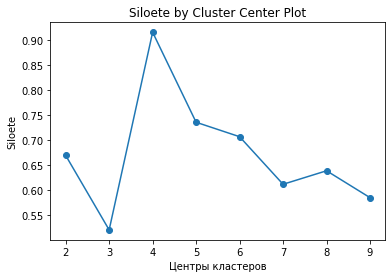

In [37]:
from sklearn_extra.cluster import KMedoids
from sklearn import metrics
#выберем оптимальное число кластеров по силуэту
iters_1 = range(2, 10, 1)
siloete_arr = []

for k in iters_1:
    kmedoids = KMedoids(n_clusters=k, random_state=14, metric='cosine').fit(X)
    siloete_arr.append(metrics.silhouette_score( metric="precomputed", X=CosDist,   labels=kmedoids.labels_ ))
   

    print('Fit {} clusters'.format(k))
    
f, ax = plt.subplots(1, 1)
ax.plot(iters_1, siloete_arr, marker='o')
ax.set_xlabel('Центры кластеров')
ax.set_xticks(iters_1)
ax.set_xticklabels(iters_1)
ax.set_ylabel('Siloete')
ax.set_title('Siloete by Cluster Center Plot')
####################
print ('Siluet')
print (siloete_arr)


Число кластеров для KMedoids - 3
Лучшее значение силуэта - метод DBScan

8. Лучший по силуэту - DBScan

9. AMI и ARI


In [40]:
kmedoids_test = KMedoids(n_clusters=4, random_state=14, metric='cosine').fit(X)

# ARI
print("ARI dbscan vs affinity propagation ", metrics.adjusted_rand_score(db.labels_, ap_cluster.labels_))

print("ARI dbscan vs KMedoids ", metrics.adjusted_rand_score(db.labels_, kmedoids_test.labels_))
print("ARI affinity propagation vs KMedoids ", metrics.adjusted_rand_score(ap_cluster.labels_, kmedoids_test.labels_))

#AMI
print("AMI dbscan vs affinity propagation ",metrics.adjusted_mutual_info_score(db.labels_, ap_cluster.labels_))

print("AMI dbscan vs KMedoids ", metrics.adjusted_mutual_info_score(db.labels_, kmedoids_test.labels_))
print("AMI affinity propagation vs KMedoids ", metrics.adjusted_mutual_info_score(ap_cluster.labels_, kmedoids_test.labels_))

ARI dbscan vs affinity propagation  0.29257830285892306
ARI dbscan vs KMedoids  0.8677760577915377
ARI affinity propagation vs KMedoids  0.20489204832008454
AMI dbscan vs affinity propagation  0.3000612447065162
AMI dbscan vs KMedoids  0.9008022984858719
AMI affinity propagation vs KMedoids  0.2666510697102825


Наиболее похожи по ARI и AMI методы dbscan и KMedodies